# Method 3 — LayoutLM (text + 2D layout)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/chundawat-h/Receipt-Invoice-Information-Extraction/blob/main/notebooks/04_layoutlm.ipynb)

**Issue #6** (Hiranya). Fine-tune `microsoft/layoutlm-base-uncased` on the same task as BERT (#5): label every OCR word as `B-/I-COMPANY`, `DATE`, `ADDRESS`, `TOTAL` or `O`. The only difference is that LayoutLM also gets **each word's box** (x0, y0, x1, y1 on a 0–1000 grid), so it can use *where* a word is on the receipt.

To keep the comparison fair, everything else is the same as BERT:
- **Same words and sub-tokens:** both models use the same uncased WordPiece vocabulary (checked in #4).
- **Same hyperparameters:** they are read from `results/bert_hparams.json`, and the notebook stops if anything differs.
- **Same base size:** 12 layers, hidden size 768.

**Run in Colab:** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all (training takes a few minutes).

Outputs saved to `results/` (same names as BERT, with `layoutlm_` in front):

| File | Contents |
|---|---|
| `layoutlm_preds.json` | field predictions per receipt key, the input to `evaluate()` and #7 |
| `layoutlm_word_preds.json` | predicted label for every word, for error analysis (#7) |
| `layoutlm_scores.csv`, `layoutlm_scores_official.csv` | field-level P/R/F1 vs tagged-word gold / official answers |
| `layoutlm_seqeval.txt` | word-level seqeval classification report |
| `layoutlm_hparams.json` | hyperparameters (identical to BERT), GPU and training time |
| `layoutlm_training_log.csv`, `layoutlm_training_loss.png`, `layoutlm_f1.png` | training curve and F1 chart |

No model weights are saved.

In [1]:
# Install the libraries Colab doesn't have (datasets<3 as pinned in requirements.txt).
# seqeval computes the entity-level report in section 5.
!pip install -q transformers "datasets<3" seqeval

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2024.6.1 which is incompatible.


In [2]:
# Why: the shared code in src/ (data loading, evaluation) is imported by every notebook, so all
# methods load and score the data in exactly the same way.
# Make `src/` importable. In a fresh Colab runtime the repo isn't there yet, so clone it.
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/chundawat-h/Receipt-Invoice-Information-Extraction.git"
if Path("../src").is_dir():            # running from notebooks/ inside the repo
    ROOT = Path("..")
elif Path("src").is_dir():
    ROOT = Path(".")
else:                                  # Colab (clone once; re-running the cell reuses it)
    ROOT = Path("Receipt-Invoice-Information-Extraction")
    if not ROOT.is_dir():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
sys.path.insert(0, str(ROOT.resolve()))
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

### Notes from data exploration (#4)
- `bboxes` are **already 0–1000**, so no normalisation is needed. Each sub-token gets its word's box; `[CLS]` → `[0,0,0,0]`, `[SEP]` → `[1000,1000,1000,1000]`, padding → `[0,0,0,0]`.
- BERT and LayoutLM have identical vocabularies, so both models see exactly the same sub-tokens. Use the same hyperparameters as notebook 03.
- Same truncation rule as 03: cut-off words get `"O"`. Save `results/layoutlm_preds.json` keyed by `row["key"]`.

In [3]:
# Word-tagged SROIE through the shared loader: the same words and labels BERT was trained on.
from src.data import LABEL2ID, LABELS, ID2LABEL, load_sroie

# Word-tagged SROIE (darentang/sroie, Parquet copy): train 626 / test 347.
# Columns: id, words, bboxes (already 0-1000), ner_tags, image_path, key.
# Save predictions keyed by row["key"] (e.g. "X51005230621"), not by row index.
ds = load_sroie()
ds

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/626 [00:00<?, ? examples/s]

Map:   0%|          | 0/347 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'words', 'bboxes', 'ner_tags', 'image_path', 'key'],
        num_rows: 626
    })
    test: Dataset({
        features: ['id', 'words', 'bboxes', 'ner_tags', 'image_path', 'key'],
        num_rows: 347
    })
})

## 1. Hyperparameters (copied from BERT)

In [4]:
# Hyperparameters copied from BERT's saved record, so the only difference between the two models is
# the layout input. The assert stops the run if anything differs from the agreed values.
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from transformers import (
    AutoTokenizer,
    DataCollatorForTokenClassification,
    LayoutLMForTokenClassification,
    Trainer,
    TrainingArguments,
    set_seed,
)

# Same values as BERT (#5), read from its saved record so the two can't drift apart
SHARED = ["max_length", "learning_rate", "epochs", "batch_size", "weight_decay", "warmup_steps",
          "lr_scheduler", "optimizer", "fp16", "seed"]
bert_record = json.loads((RESULTS / "bert_hparams.json").read_text())
HP = {"model": "microsoft/layoutlm-base-uncased", **{k: bert_record[k] for k in SHARED}}

EXPECTED = {"max_length": 512, "learning_rate": 5e-5, "epochs": 10, "batch_size": 8, "fp16": True, "seed": 42}
assert all(HP[k] == v for k, v in EXPECTED.items()), f"BERT hyperparameters changed: {HP}"

GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else None
# BERT was trained with fp16 on a GPU; LayoutLM must run under the same conditions.
if GPU is None:
    raise RuntimeError("No GPU: in Colab use Runtime -> Change runtime type -> T4 GPU. "
                     "(BERT was trained with fp16 on a T4; LayoutLM must match.)")
print("GPU:", GPU, "| transformers", transformers.__version__, "| torch", torch.__version__)
# Same seed as BERT: same classifier-head initialisation and data order.
set_seed(HP["seed"])
pd.DataFrame(HP.items(), columns=["hyperparameter", "value"]).set_index("hyperparameter")

GPU: Tesla T4 | transformers 5.22.1 | torch 2.14.1+cu130


,value
hyperparameter,
model,microsoft/layoutlm-base-uncased
max_length,512
learning_rate,0.00005
epochs,10
batch_size,8
weight_decay,0.0
warmup_steps,0
lr_scheduler,linear
optimizer,AdamW (Trainer default)


## 2. Tokenise, align labels and add boxes

Labels work exactly as for BERT: only the first sub-token of each word carries the word's label, and everything else gets `-100`.

**New for LayoutLM:** every sub-token also gets a `bbox`:
- Each sub-token gets the box of the word it comes from. The boxes are already 0–1000 (checked in #4), so no normalisation is needed.
- `[CLS]` → `[0, 0, 0, 0]` and `[SEP]` → `[1000, 1000, 1000, 1000]`.
- Padding → `[0, 0, 0, 0]`. This is added by the collator in the next section.

In [5]:
# Same tokenisation and label alignment as BERT, plus one box per sub-token (LayoutLM's extra input).
# The checks at the end catch alignment mistakes before any training.
tokenizer = AutoTokenizer.from_pretrained(HP["model"])
MAX_LEN = HP["max_length"]
CLS_BOX, SEP_BOX, PAD_BOX = [0, 0, 0, 0], [1000, 1000, 1000, 1000], [0, 0, 0, 0]
# Padding must be on the right, because the collator appends the padding boxes at the end.
assert tokenizer.padding_side == "right"

def align_labels(word_ids, word_tags):
    # First sub-token of each word -> the word's tag; everything else -> -100 (ignored by the loss)
    labels, previous = [], None
    for w in word_ids:
        labels.append(-100 if w is None or w == previous else word_tags[w])
        previous = w
    return labels

def align_boxes(word_ids, input_ids, word_boxes):
    # Every sub-token gets its word's box; [CLS] -> CLS_BOX, [SEP] -> SEP_BOX
    boxes = []
    for w, token_id in zip(word_ids, input_ids):
        if w is not None:
            boxes.append(list(word_boxes[w]))
        else:
            boxes.append(SEP_BOX if token_id == tokenizer.sep_token_id else CLS_BOX)
    return boxes

def encode(batch):
    enc = tokenizer(batch["words"], is_split_into_words=True, truncation=True, max_length=MAX_LEN)
    enc["labels"], enc["bbox"] = [], []
    for i, (tags, word_boxes) in enumerate(zip(batch["ner_tags"], batch["bboxes"])):
        word_ids = enc.word_ids(i)
        enc["labels"].append(align_labels(word_ids, tags))
        enc["bbox"].append(align_boxes(word_ids, enc["input_ids"][i], word_boxes))
    return enc

encoded = ds.map(encode, batched=True, remove_columns=ds["train"].column_names)

# Sanity checks: one box per sub-token, all inside 0-1000, [CLS]/[SEP] boxes in place
for split in encoded:
    for ex in encoded[split]:
        assert len(ex["bbox"]) == len(ex["input_ids"]) == len(ex["labels"])
        assert ex["bbox"][0] == CLS_BOX and ex["bbox"][-1] == SEP_BOX
        assert all(0 <= v <= 1000 for box in ex["bbox"] for v in box)
print("bbox checks passed")
encoded

config.json:   0%|          | 0.00/606 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/170 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/626 [00:00<?, ? examples/s]

Map:   0%|          | 0/347 [00:00<?, ? examples/s]

bbox checks passed


DatasetDict({
    train: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels', 'bbox'],
        num_rows: 626
    })
    test: Dataset({
        features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels', 'bbox'],
        num_rows: 347
    })
})

In [6]:
# Check boxes and labels by eye before training.
# What the model sees for the start of one receipt: same sub-tokens and labels as BERT, plus a box each
row, enc = ds["train"][0], encoded["train"][0]
word_ids = tokenizer(row["words"], is_split_into_words=True, truncation=True, max_length=MAX_LEN).word_ids()
pd.DataFrame({
    "sub-token": tokenizer.convert_ids_to_tokens(enc["input_ids"]),
    "word": [row["words"][w] if w is not None else "" for w in word_ids],
    "bbox": enc["bbox"],
    "label": [ID2LABEL[l] if l != -100 else "-100 (ignored)" for l in enc["labels"]],
}).head(25)

,sub-token,word,bbox,label
0,[CLS],,"[0, 0, 0, 0]",-100 (ignored)
1,tan,tan,"[157, 29, 280, 58]",O
2,woo,woon,"[293, 30, 503, 60]",O
3,##n,woon,"[293, 30, 503, 60]",-100 (ignored)
4,yan,yann,"[518, 32, 697, 61]",O
5,##n,yann,"[518, 32, 697, 61]",-100 (ignored)
6,book,BOOK,"[151, 92, 276, 111]",B-COMPANY
7,ta,TA,"[282, 91, 332, 111]",I-COMPANY
8,_,_K,"[339, 91, 384, 111]",I-COMPANY
9,k,_K,"[339, 91, 384, 111]",-100 (ignored)


## 3. Train

The standard `DataCollatorForTokenClassification` pads `input_ids`, `attention_mask` and `labels`, but not `bbox`. The small collator below pads the boxes with `[0, 0, 0, 0]` to the same length.

In [7]:
# The standard collator pads text and labels but not bbox, so batches with receipts of different
# lengths would fail. The sample batch shows bbox gets shape (batch, length, 4).
def pad_boxes(boxes, length):
    return [list(b) for b in boxes] + [PAD_BOX] * (length - len(boxes))

class LayoutLMCollator:
    def __init__(self, tokenizer):
        self.text = DataCollatorForTokenClassification(tokenizer)

    def __call__(self, features):
        features = [dict(f) for f in features]
        boxes = [f.pop("bbox") for f in features]
        batch = self.text(features)
        length = batch["input_ids"].shape[1]
        batch["bbox"] = torch.tensor([pad_boxes(b, length) for b in boxes], dtype=torch.long)
        return batch

collator = LayoutLMCollator(tokenizer)
sample = collator([encoded["train"][i] for i in range(3)])
print({k: tuple(v.shape) for k, v in sample.items()})

{'input_ids': (3, 297), 'token_type_ids': (3, 297), 'attention_mask': (3, 297), 'labels': (3, 297), 'bbox': (3, 297, 4)}


In [8]:
# Fine-tune LayoutLM with exactly BERT's training arguments (epochs, learning rate, batch, seed, no checkpoints).
model = LayoutLMForTokenClassification.from_pretrained(
    HP["model"], num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID
)

args = TrainingArguments(
    output_dir="outputs/layoutlm",       # git-ignored; nothing is saved there (save_strategy="no")
    learning_rate=HP["learning_rate"],
    num_train_epochs=HP["epochs"],
    per_device_train_batch_size=HP["batch_size"],
    per_device_eval_batch_size=16,
    weight_decay=HP["weight_decay"],
    warmup_steps=HP["warmup_steps"],
    lr_scheduler_type=HP["lr_scheduler"],
    fp16=HP["fp16"],
    seed=HP["seed"],
    eval_strategy="no",                  # no validation split; test is used once, after training
    save_strategy="no",                  # no checkpoints / weights
    logging_steps=10,
    report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=encoded["train"],
    data_collator=collator,
    processing_class=tokenizer,
)

start = time.time()
train_result = trainer.train()
TRAIN_MINUTES = (time.time() - start) / 60
print(f"Training took {TRAIN_MINUTES:.1f} min on {GPU}")
train_result.metrics

model.safetensors: reconstructing file:   0%|          |  0.00B /  451MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] LayoutLMForTokenClassification LOAD REPORT from: microsoft/layoutlm-base-uncased
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
10,1.622017
20,0.383290
30,0.205187
40,0.115437
50,0.096663
60,0.080139
70,0.075771
80,0.060051
90,0.043262
100,0.049951


Training took 2.5 min on Tesla T4


{'train_runtime': 147.0183,
 'train_samples_per_second': 42.58,
 'train_steps_per_second': 5.373,
 'total_flos': 1172885074001784.0,
 'train_loss': 0.044616301802187404,
 'epoch': 10.0}

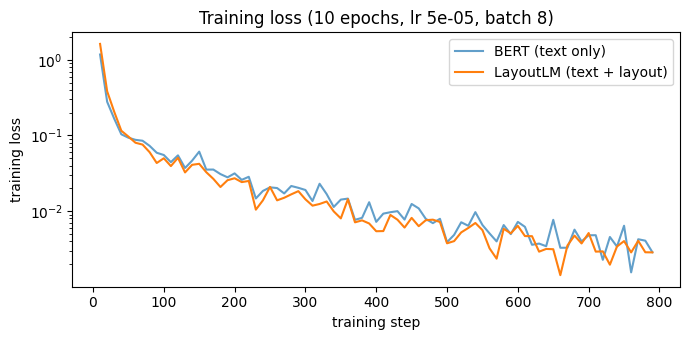

In [9]:
# Training loss of both models in one figure (results/layoutlm_training_loss.png), used in the report.
log = pd.DataFrame([h for h in trainer.state.log_history if "loss" in h])
log.to_csv(RESULTS / "layoutlm_training_log.csv", index=False)

bert_log = pd.read_csv(RESULTS / "bert_training_log.csv")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(bert_log["step"], bert_log["loss"], label="BERT (text only)", alpha=0.7)
ax.plot(log["step"], log["loss"], label="LayoutLM (text + layout)")
ax.set_xlabel("training step")
ax.set_ylabel("training loss")
# Log scale: the loss falls by three orders of magnitude; a linear axis would hide the later epochs.
ax.set_yscale("log")
ax.set_title(f"Training loss ({HP['epochs']} epochs, lr {HP['learning_rate']}, batch {HP['batch_size']})")
ax.legend()
fig.tight_layout()
fig.savefig(RESULTS / "layoutlm_training_loss.png", dpi=150)
plt.show()

## 4. Predict on the test set (word level)

This works the same way as BERT: each word takes the prediction of its first sub-token, and words cut off by truncation get `O`.

In [10]:
# Predict the test set and turn sub-token predictions back into one label per word (same as BERT).
# Saved for the error analysis in notebook 05.
def to_word_labels(n_words, word_ids, token_pred):
    labels = ["O"] * n_words          # words cut off by truncation stay "O"
    seen = set()
    for position, w in enumerate(word_ids):
        if w is None or w in seen:
            continue
        seen.add(w)
        labels[w] = ID2LABEL[int(token_pred[position])]
    return labels

test = ds["test"]
token_preds = trainer.predict(encoded["test"]).predictions.argmax(-1)
# Re-tokenise to get each sub-token's word index, needed to map predictions back to words.
test_word_ids = [
    tokenizer(r["words"], is_split_into_words=True, truncation=True, max_length=MAX_LEN).word_ids() for r in test
]
word_preds = {
    r["key"]: to_word_labels(len(r["words"]), wid, pred)
    for r, wid, pred in zip(test, test_word_ids, token_preds)
}

with open(RESULTS / "layoutlm_word_preds.json", "w", encoding="utf-8") as f:
    json.dump(word_preds, f)
print(f"Word-level predictions for {len(word_preds)} test receipts saved")

Word-level predictions for 347 test receipts saved


## 5. seqeval report (word level)

In [11]:
# Entity-level scores on the word labels: an entity is correct only if all its words and its type are right.
from seqeval.metrics import classification_report

y_true = [[ID2LABEL[t] for t in r["ner_tags"]] for r in test]
y_pred = [word_preds[r["key"]] for r in test]
report = classification_report(y_true, y_pred, digits=4)
(RESULTS / "layoutlm_seqeval.txt").write_text(report)
print(report)

              precision    recall  f1-score   support

     ADDRESS     0.9176    0.9308    0.9242       347
     COMPANY     0.9252    0.9625    0.9435       347
        DATE     0.9855    0.9827    0.9841       347
       TOTAL     0.8371    0.8588    0.8478       347

   micro avg     0.9159    0.9337    0.9247      1388
   macro avg     0.9164    0.9337    0.9249      1388
weighted avg     0.9164    0.9337    0.9249      1388



## 6. Field-level scores (`src/evaluate.py`, same as every method)

In [12]:
# Field strings from the word labels (bio_to_fields), saved as results/layoutlm_preds.json and scored
# with the shared evaluate() against both golds, exactly like BERT and the regex baseline.
from src.evaluate import bio_to_fields, compare, evaluate, get_gold, get_official_gold, load_preds, normalize, save_preds

layoutlm_preds = {r["key"]: bio_to_fields(r["words"], word_preds[r["key"]]) for r in test}
save_preds(layoutlm_preds, RESULTS / "layoutlm_preds.json")

gold_test = get_gold(test)
official_gold = get_official_gold("test", keys=test["key"])   # streams the official answers (~1 min)

print("TEST, main gold (word tags)")
test_scores = evaluate(layoutlm_preds, gold_test)
test_scores.to_csv(RESULTS / "layoutlm_scores.csv")
print(test_scores.to_string())

print("\nTEST, official ICDAR answers")
official_scores = evaluate(layoutlm_preds, official_gold)
official_scores.to_csv(RESULTS / "layoutlm_scores_official.csv")
print(official_scores.to_string())

ceiling = evaluate(gold_test, official_gold)["f1"]

TEST, main gold (word tags)
           precision  recall     f1  correct  predicted  gold
field                                                        
company        93.31   92.51  92.91      321        344   347
date           98.84   98.56  98.70      342        346   347
address        93.66   93.66  93.66      325        347   347
total          90.80   88.18  89.47      306        337   347
macro_avg      94.15   93.23  93.69     <NA>       <NA>  <NA>

TEST, official ICDAR answers
           precision  recall     f1  correct  predicted  gold
field                                                        
company        75.58   74.93  75.25      260        344   347
date           96.24   95.97  96.10      333        346   347
address        57.06   57.06  57.06      198        347   347
total          87.24   84.73  85.96      294        337   347
macro_avg      79.03   78.17  78.60     <NA>       <NA>  <NA>


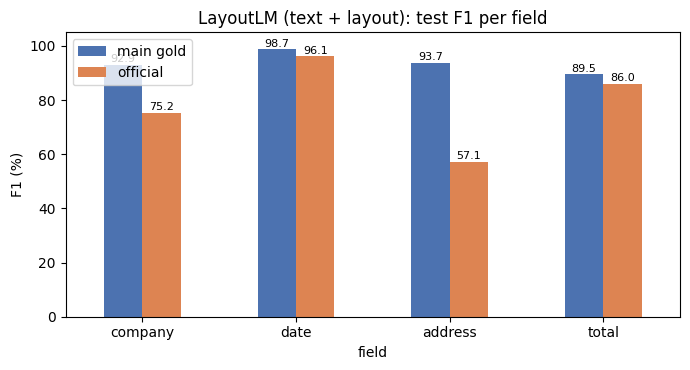

In [13]:
# F1 per field against both golds (results/layoutlm_f1.png).
f1 = pd.DataFrame({"main gold": test_scores["f1"], "official": official_scores["f1"]}).drop("macro_avg")
ax = f1.plot.bar(rot=0, figsize=(7, 3.8), color=["#4C72B0", "#DD8452"])
ax.set_ylim(0, 105)
ax.set_ylabel("F1 (%)")
ax.set_title("LayoutLM (text + layout): test F1 per field")
for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height() + 1), ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "layoutlm_f1.png", dpi=150)
plt.show()

## 7. First look: how much does layout add?

This is a quick comparison with the saved regex and BERT predictions, scored by the same `compare()`. `layout_gain` = LayoutLM F1 − BERT F1. The full analysis (chart, error analysis, write-up) is #7.

In [14]:
# First look at the research question: the same compare() as notebook 05, with
# layout_gain = LayoutLM F1 - BERT F1.
method_preds = {
    "Regex": load_preds(RESULTS / "regex_preds.json"),
    "BERT": load_preds(RESULTS / "bert_preds.json"),
    "LayoutLM": layoutlm_preds,
}
print("F1 vs tagged-word gold (main)")
print(compare(method_preds, gold_test).to_string())
print("\nF1 vs official ICDAR answers (perfect-tagger ceiling in the last column)")
official_table = compare(method_preds, official_gold)
official_table["ceiling"] = ceiling
print(official_table.round(2).to_string())

F1 vs tagged-word gold (main)
           Regex   BERT  LayoutLM  layout_gain
field                                         
company    68.30  89.31     92.91         3.60
date       95.79  97.84     98.70         0.86
address    59.94  91.07     93.66         2.59
total      75.22  89.37     89.47         0.10
macro_avg  74.81  91.90     93.69         1.79

F1 vs official ICDAR answers (perfect-tagger ceiling in the last column)
           Regex   BERT  LayoutLM  layout_gain  ceiling
field                                                  
company    57.64  72.83     75.25         2.42    80.40
date       95.79  94.95     96.10         1.15    96.25
address    40.92  55.62     57.06         1.44    58.21
total      77.23  86.46     85.96        -0.50    96.25
macro_avg  67.90  77.47     78.60         1.13    82.78


## 8. Where LayoutLM fails (examples for the report)

In [15]:
# Failures per field, and how many receipts LayoutLM gets right where BERT was wrong (layout helping).
bert_preds = method_preds["BERT"]
for field in ["company", "address", "total", "date"]:
    wrong = [k for k, g in gold_test.items() if normalize(layoutlm_preds[k][field], field) != normalize(g[field], field)]
    fixed = [k for k, g in gold_test.items()
             if normalize(layoutlm_preds[k][field], field) == normalize(g[field], field)
             and normalize(bert_preds[k][field], field) != normalize(g[field], field)]
    print(f"=== {field}: LayoutLM wrong on {len(wrong)} / {len(gold_test)} | right where BERT was wrong: {len(fixed)} ===")
    for k in wrong[:3]:
        print(f"  [{k}] PRED: {layoutlm_preds[k][field]!r}\n                 GOLD: {gold_test[k][field]!r}")
    print()

=== company: LayoutLM wrong on 26 / 347 | right where BERT was wrong: 20 ===
  [X51005230605] PRED: 'PETRON BKT LANJAN SB ALSERKAM ENTERPRISE'
                 GOLD: 'PETRON BKT LANJAN SB'
  [X51005230621] PRED: 'SIN LIANHAP SON BHD SON BHD'
                 GOLD: 'SIN LIANHAP SON BHD'
  [X51005444040] PRED: "Der's Grocer BENS INDEPENDENT GROCER SDN. BHD"
                 GOLD: 'BENS INDEPENDENT GROCER SDN. BHD'

=== address: LayoutLM wrong on 22 / 347 | right where BERT was wrong: 10 ===
  [X51005230621] PRED: 'LOT 13, JALAN SIN LIANHAP LOT 13, JALAN IPOH, KG BATU 30 , ULU YAM LAMA 44300 BTG KALI, SELANGOR.'
                 GOLD: 'LOT 13, JALAN IPOH, KG BATU 30 , ULU YAM LAMA 44300 BTG KALI, SELANGOR.'
  [X51005337867] PRED: 'Rampai'
                 GOLD: 'Sri Rampai'
  [X51005361908] PRED: 'NO. 53, JALAN BESAR, 45600 BATANG BERJOMAT SELANGOR DARUL EHSAN'
                 GOLD: '(001451637-M)" NO. 53, JALAN BESAR, 45600 BATANG BERJOMAT SELANGOR DARUL EHSAN'

=== total: LayoutLM wron

## 9. Summary, hyperparameters and download

In [16]:
# Summary table and the run record (hyperparameters identical to BERT, GPU, time, library versions).
summary = pd.DataFrame({
    "LayoutLM F1, main gold": test_scores["f1"],
    "LayoutLM F1, official": official_scores["f1"],
    "perfect-tagger ceiling (official)": ceiling,
}).round(1)
print(summary.to_string())

record = {
    **HP,
    "gpu": GPU,
    "train_minutes": round(TRAIN_MINUTES, 1),
    "train_receipts": len(ds["train"]),
    "test_receipts": len(test),
    "transformers": transformers.__version__,
    "torch": torch.__version__,
}
(RESULTS / "layoutlm_hparams.json").write_text(json.dumps(record, indent=2))
record

           LayoutLM F1, main gold  LayoutLM F1, official  perfect-tagger ceiling (official)
field                                                                                      
company                      92.9                   75.2                               80.4
date                         98.7                   96.1                               96.2
address                      93.7                   57.1                               58.2
total                        89.5                   86.0                               96.2
macro_avg                    93.7                   78.6                               82.8


{'model': 'microsoft/layoutlm-base-uncased',
 'max_length': 512,
 'learning_rate': 5e-05,
 'epochs': 10,
 'batch_size': 8,
 'weight_decay': 0.0,
 'warmup_steps': 0,
 'lr_scheduler': 'linear',
 'optimizer': 'AdamW (Trainer default)',
 'fp16': True,
 'seed': 42,
 'gpu': 'Tesla T4',
 'train_minutes': 2.5,
 'train_receipts': 626,
 'test_receipts': 347,
 'transformers': '5.22.1',
 'torch': '2.14.1+cu130'}

In Colab, the next cell downloads all `results/layoutlm_*` files as one zip.
- **Extract the files straight into the repo's `results/` folder**, not into a `layoutlm_results/` subfolder.
- Save this notebook with **File → Save a copy in GitHub**: branch `model/layoutlm`, file path exactly `notebooks/04_layoutlm.ipynb`, and untick "Include a link to Colaboratory".

In [17]:
# In Colab the results live in a temporary runtime: download all results/layoutlm_* files as one zip.
import zipfile

layoutlm_files = sorted(RESULTS.glob("layoutlm_*"))
print("\n".join(p.name for p in layoutlm_files))
try:
    from google.colab import files
except ImportError:
    files = None                      # running locally: the files are already in results/
if files is not None:
    with zipfile.ZipFile("layoutlm_results.zip", "w") as z:
        for p in layoutlm_files:
            z.write(p, p.name)
    files.download("layoutlm_results.zip")

layoutlm_f1.png
layoutlm_hparams.json
layoutlm_preds.json
layoutlm_scores.csv
layoutlm_scores_official.csv
layoutlm_seqeval.txt
layoutlm_training_log.csv
layoutlm_training_loss.png
layoutlm_word_preds.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>